Iteration 20: Best Fitness = 147.60
Iteration 40: Best Fitness = 140.08
Iteration 60: Best Fitness = 140.08
Iteration 80: Best Fitness = 140.08
Iteration 100: Best Fitness = 140.08
Iteration 120: Best Fitness = 140.08
Iteration 140: Best Fitness = 140.08
Iteration 160: Best Fitness = 140.08
Iteration 180: Best Fitness = 140.08
Iteration 200: Best Fitness = 140.08

========== OPTIMIZATION RESULTS ==========
Best Fitness Value: 140.08
Initial Electricity Cost: 145.3
Optimized Electricity Cost: 130.4
Electricity Cost Savings: 14.9
Savings Percentage: 10.25 %
Peak Power Demand: 2.2 kW
Total Energy Consumption: 21.8 kWh

========== OPTIMAL APPLIANCE SCHEDULE ==========


,Appliance,Start Time,End Time,Power (kW)
0,Air Conditioner,0:00,6:00,1.5
1,Washing Machine,8:00,10:00,0.8
2,Dishwasher,15:00,17:00,1.2
3,Water Heater,6:00,8:00,2.0
4,Refrigerator,00:00,24:00,0.2


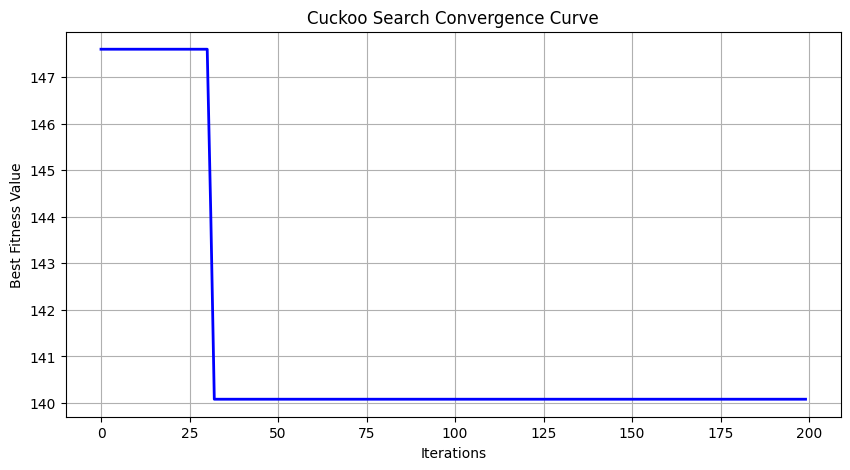

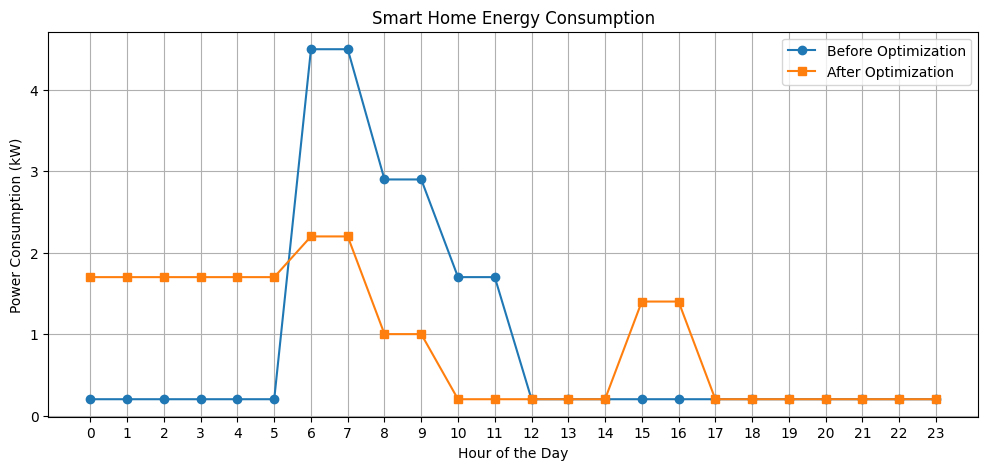

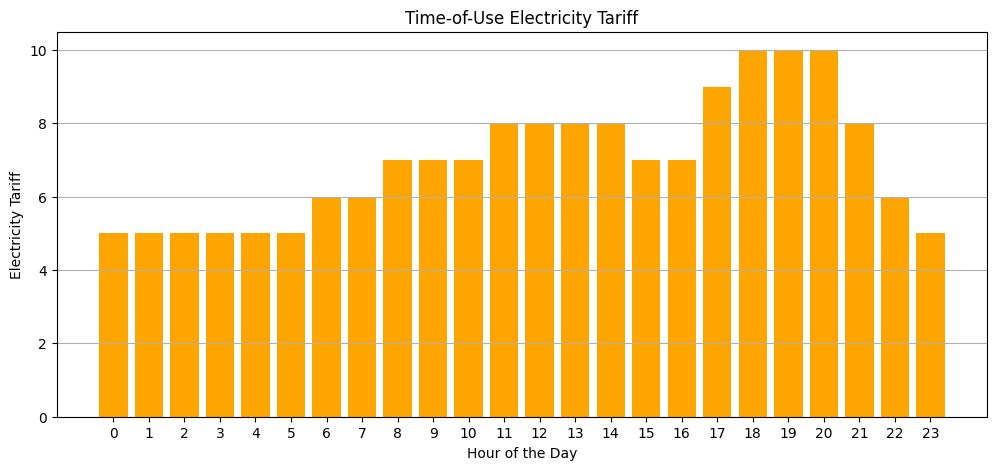

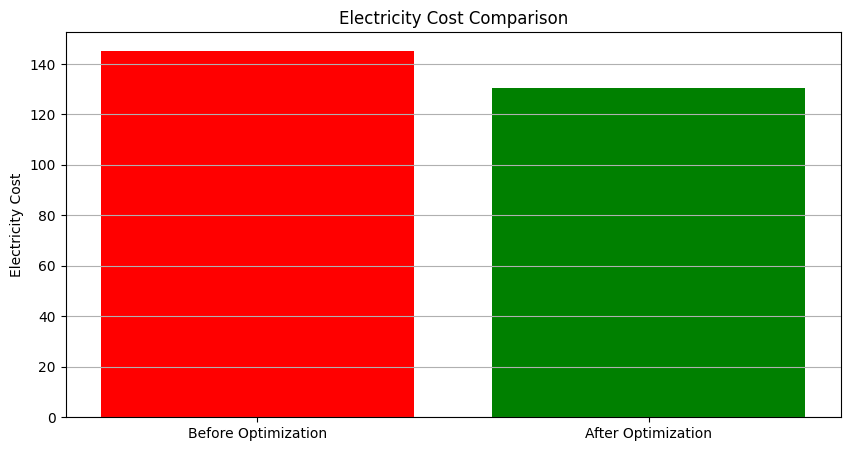


Cuckoo Search Smart Home Energy Management Completed Successfully!


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import gamma

np.random.seed(42)

HOURS = 24

appliances = [
    "Air Conditioner",
    "Washing Machine",
    "Dishwasher",
    "Water Heater",
    "Refrigerator"
]

power = np.array([1.5, 0.8, 1.2, 2.0, 0.2])
duration = np.array([6, 2, 2, 2, 24])

tariff = np.array([
    5, 5, 5, 5, 5, 5,
    6, 6, 7, 7, 7, 8,
    8, 8, 8, 7, 7, 9,
    10, 10, 10, 8, 6, 5
])

start_min = np.array([0, 6, 8, 5, 0])
start_max = np.array([18, 20, 18, 20, 0])

n_nests = 25
discovery_rate = 0.25
max_iterations = 200
dimension = 4
beta = 1.5
alpha = 0.01

lower_bound = start_min[:4]
upper_bound = start_max[:4]


def calculate_load(schedule):
    hourly_load = np.zeros(24)
    start_times = np.round(schedule).astype(int)
    start_times = np.clip(start_times, lower_bound, upper_bound)

    for i in range(4):
        start = start_times[i]
        end = start + duration[i]
        hourly_load[start:end] += power[i]

    hourly_load += power[4]

    return hourly_load


def objective(schedule):
    hourly_load = calculate_load(schedule)
    energy_cost = np.sum(hourly_load * tariff)
    peak_load = np.max(hourly_load)
    penalty = 2.0 * (peak_load ** 2)
    return energy_cost + penalty


def levy_flight(beta, size):
    sigma_u = (
        gamma(1 + beta) *
        np.sin(np.pi * beta / 2) /
        (
            gamma((1 + beta) / 2) *
            beta *
            2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma_u, size)
    v = np.random.normal(0, 1, size)

    return u / (np.abs(v) ** (1 / beta))


def cuckoo_search():

    nests = np.random.uniform(
        lower_bound,
        upper_bound,
        (n_nests, dimension)
    )

    fitness = np.array([
        objective(nest) for nest in nests
    ])

    best_index = np.argmin(fitness)
    best_nest = nests[best_index].copy()
    best_fitness = fitness[best_index]

    convergence = []

    for iteration in range(max_iterations):

        for i in range(n_nests):

            step = levy_flight(beta, dimension)

            new_nest = nests[i] + alpha * step * (
                nests[i] - best_nest
            )

            new_nest = np.clip(
                new_nest,
                lower_bound,
                upper_bound
            )

            new_fitness = objective(new_nest)

            j = np.random.randint(n_nests)

            if new_fitness < fitness[j]:
                nests[j] = new_nest
                fitness[j] = new_fitness

        n_abandon = int(discovery_rate * n_nests)

        worst_indices = np.argsort(fitness)[-n_abandon:]

        for index in worst_indices:

            nests[index] = np.random.uniform(
                lower_bound,
                upper_bound,
                dimension
            )

            fitness[index] = objective(nests[index])

        best_index = np.argmin(fitness)

        if fitness[best_index] < best_fitness:
            best_fitness = fitness[best_index]
            best_nest = nests[best_index].copy()

        convergence.append(best_fitness)

        if (iteration + 1) % 20 == 0:
            print(
                f"Iteration {iteration + 1}: "
                f"Best Fitness = {best_fitness:.2f}"
            )

    return best_nest, best_fitness, convergence


best_schedule, best_cost, convergence = cuckoo_search()

optimized_load = calculate_load(best_schedule)
optimized_cost = np.sum(optimized_load * tariff)
peak_demand = np.max(optimized_load)
total_energy = np.sum(optimized_load)

initial_schedule = np.array([6, 6, 6, 6])
initial_load = calculate_load(initial_schedule)
initial_cost = np.sum(initial_load * tariff)

savings = initial_cost - optimized_cost
savings_percentage = (savings / initial_cost) * 100

print("\n========== OPTIMIZATION RESULTS ==========")
print("Best Fitness Value:", round(best_cost, 2))
print("Initial Electricity Cost:", round(initial_cost, 2))
print("Optimized Electricity Cost:", round(optimized_cost, 2))
print("Electricity Cost Savings:", round(savings, 2))
print("Savings Percentage:", round(savings_percentage, 2), "%")
print("Peak Power Demand:", round(peak_demand, 2), "kW")
print("Total Energy Consumption:", round(total_energy, 2), "kWh")

print("\n========== OPTIMAL APPLIANCE SCHEDULE ==========")

schedule_data = []

for i in range(4):
    start = int(round(best_schedule[i]))
    end = start + duration[i]

    schedule_data.append([
        appliances[i],
        f"{start}:00",
        f"{end}:00",
        power[i]
    ])

schedule_data.append([
    "Refrigerator",
    "00:00",
    "24:00",
    power[4]
])

df = pd.DataFrame(
    schedule_data,
    columns=[
        "Appliance",
        "Start Time",
        "End Time",
        "Power (kW)"
    ]
)

display(df)

hours = np.arange(24)

plt.figure(figsize=(10, 5))
plt.plot(convergence, color="blue", linewidth=2)
plt.title("Cuckoo Search Convergence Curve")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness Value")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(hours, initial_load, marker="o", label="Before Optimization")
plt.plot(hours, optimized_load, marker="s", label="After Optimization")
plt.xlabel("Hour of the Day")
plt.ylabel("Power Consumption (kW)")
plt.title("Smart Home Energy Consumption")
plt.xticks(hours)
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))
plt.bar(hours, tariff, color="orange")
plt.xlabel("Hour of the Day")
plt.ylabel("Electricity Tariff")
plt.title("Time-of-Use Electricity Tariff")
plt.xticks(hours)
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(
    ["Before Optimization", "After Optimization"],
    [initial_cost, optimized_cost],
    color=["red", "green"]
)
plt.ylabel("Electricity Cost")
plt.title("Electricity Cost Comparison")
plt.grid(axis="y")
plt.show()

print("\nCuckoo Search Smart Home Energy Management Completed Successfully!")
